# Practice Notebook 2: Sampling Distributions, the CLT, and Confidence Intervals

This practice notebook has two parts:

1. **Paper and pencil:** short questions that apply the lecture definitions and formulas.
2. **Python and interpretation:** three questions using brain-science examples.

For Part 1, write the reasoning as well as the final answer. For Part 2, run each cell and answer the interpretation questions before changing the code.

## Learning goals

By the end of the session, you should be able to:

- distinguish standard deviation and standard error, for means and proportions
- apply the Central Limit Theorem to continuous and binary (Bernoulli) data
- choose between z and t critical values
- compute confidence intervals and interpret them correctly
- plan a sample size for a desired precision


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)


# Part 1: Paper-and-pencil questions

Complete these questions without Python. You can use the calculator.


## 1. Standard deviation vs. standard error

Resting alpha power is measured in $n=25$ participants: $\bar x=42$ µV², $s=10$ µV².

1. Calculate the standard error of the mean.
2. Which quantity, $s$ or $SE$, describes how much participants differ from one another? Which describes the uncertainty of $\bar x$?
3. How many participants would be needed for $SE=1$ µV²?
4. The study is repeated with four times as many participants. What do you expect for $s$ and for $SE$?


### Solution

1. $$SE=\frac{s}{\sqrt n}=\frac{10}{\sqrt{25}}=2\text{ µV}^2.$$

2. $s$ describes the spread **among participants**. $SE$ describes the sampling variability of $\bar x$, that is, how much the mean would vary across repeated samples.

3. $$\frac{10}{\sqrt n}=1\ \Rightarrow\ \sqrt n=10\ \Rightarrow\ n=100.$$

4. $s$ stays about 10 µV², because it estimates the population SD, which does not depend on $n$. $SE$ halves to about $10/\sqrt{100}=1$ µV², because $\sqrt{4n}=2\sqrt n$.


## 2. Sampling distribution of a proportion

In a lexical-decision task, each trial of one participant is correct with probability $p=0.8$, independently. Let $\hat p$ be the proportion of correct trials out of $n$ trials.

1. A single trial is a Bernoulli variable. Give its mean and standard deviation $\sigma$.
2. For $n=64$ trials, find $E(\hat p)$ and $SE(\hat p)=\sigma/\sqrt n$.
3. Use the CLT and $P(Z<-2)\approx0.023$ to approximate $P(\hat p<0.70)$ for $n=64$.
4. Why is the normal approximation poor for $n=1$ or $n=2$?
5. How many trials are needed to halve the standard error obtained for $n=64$?


### Solution

1. Mean $p=0.8$. Variance $p(1-p)=0.16$, so $\sigma=\sqrt{0.16}=0.4$.

2. $$E(\hat p)=p=0.8,\qquad SE(\hat p)=\frac{0.4}{\sqrt{64}}=\frac{0.4}{8}=0.05.$$

3. $$z=\frac{0.70-0.80}{0.05}=-2,\qquad P(\hat p<0.70)\approx P(Z<-2)\approx0.023.$$

4. For $n=1$, $\hat p$ takes only the values 0 and 1. For $n=2$, it takes 0, 0.5, and 1. These sampling distributions have very few values and are skewed because $p=0.8$ is far from 0.5. The CLT is a large-$n$ approximation.

5. Halving $SE$ requires four times as many trials: $4\times64=256$.


## 3. What the Central Limit Theorem does and does not say

Decide whether each statement is true or false, and correct the false ones.

1. The CLT states that the raw data become normally distributed when $n$ is large.
2. The CLT requires the population distribution to be normal.
3. The mean of the sampling distribution of $\bar X$ equals $\mu$.
4. For $n=50$ right-skewed reaction times (i.i.d., finite variance), $\bar X\approx N(\mu,\sigma^2/50)$.
5. The CLT also applies to averages of 0/1 outcomes.

Finally, explain in one or two sentences why the CLT matters for statistical inference.


### Solution

1. **False.** The CLT concerns the sampling distribution of the (standardized) sample mean. Raw data keep their own shape.
2. **False.** It requires i.i.d. observations with finite mean $\mu$ and finite variance $\sigma^2$. The population can be skewed or discrete.
3. **True.** The mean of all sample means equals $\mu$ (unbiasedness under random sampling).
4. **True**, approximately. For large $n$, $(\bar X-\mu)/(\sigma/\sqrt n)\approx N(0,1)$.
5. **True.** A proportion is the average of Bernoulli variables, so it is approximately normal for large $n$.

**Why it matters:** the CLT lets us use normal (or $t$) critical values for means even when raw data are not normal. This justifies confidence intervals and hypothesis tests and allows generalization from sample to population.


## 4. z vs. t and a confidence interval for a mean

Hippocampal volume is measured in $n=10$ participants: $\bar x=3.90$ cm³, $s=0.40$ cm³. The population SD is unknown.

| | $z$ | $t$, df = 4 | $t$, df = 9 | $t$, df = 29 | $t$, df = 99 |
|---|---|---|---|---|---|
| 97.5th percentile | 1.960 | 2.776 | 2.262 | 2.045 | 1.984 |

1. Which critical value should be used, and why?
2. Compute the 95% confidence interval.
3. Compute the interval obtained when 1.96 is (incorrectly) used. Compare the widths. What is the consequence?
4. Describe how the $t$ critical value changes as the degrees of freedom increase, and explain why.


### Solution

1. Use $t$ with $df=n-1=9$, so $t=2.262$. $\sigma$ is unknown and estimated by $s$, and the sample is small.

2. $$SE=\frac{0.40}{\sqrt{10}}\approx0.1265,\qquad 3.90\pm2.262(0.1265)=3.90\pm0.286=[3.61,\ 4.19]\text{ cm}^3.$$

3. $$3.90\pm1.96(0.1265)=3.90\pm0.248=[3.65,\ 4.15]\text{ cm}^3.$$

The z-interval is narrower because it ignores the extra uncertainty from estimating $\sigma$ with $s$. As a result, it contains $\mu$ in fewer than 95% of repeated studies (undercoverage).

4. The $t$ critical value decreases towards 1.96 as $df$ increases (2.776 → 2.262 → 2.045 → 1.984). With few degrees of freedom, $s$ is an imprecise estimate of $\sigma$, so the $t$ distribution has heavier tails. With more data, $s$ becomes precise and $t$ approaches the normal distribution.


## 5. Interpreting a confidence interval

Use the interval $[3.61,\ 4.19]$ cm³ from Question 4.

1. "95% of individual participants have a hippocampal volume between 3.61 and 4.19 cm³." Correct?
2. "If the study were repeated many times, about 95% of intervals constructed this way would contain $\mu$." Correct?
3. "There is a 95% probability that $\mu$ lies in $[3.61,\ 4.19]$." Explain the problem with this wording.
4. Would a two-sided test at $\alpha=0.05$ reject $H_0:\mu=4.20$? And $H_0:\mu=4.00$?
5. Another lab measures $n=40$ participants with the same $s$ ($t_{0.975,39}\approx2.023$). Compute its margin of error and compare.


### Solution

1. **Incorrect.** The interval concerns the population **mean**, not individual values. Individual volumes vary much more (SD 0.40).
2. **Correct.** This is the repeated-sampling interpretation: about 95 of 100 such intervals contain $\mu$, and about 5 do not.
3. $\mu$ is a fixed number, so this specific interval either contains it or not. The 95% describes the long-run success rate of the **procedure**, not the probability for one computed interval.
4. $4.20$ lies outside the interval, so reject $H_0:\mu=4.20$. $4.00$ lies inside, so do not reject $H_0:\mu=4.00$.
5. $$SE=\frac{0.40}{\sqrt{40}}\approx0.0632,\qquad \text{margin}=2.023(0.0632)\approx0.128\text{ cm}^3.$$

This is less than half the margin for $n=10$ (0.286), because of the larger $\sqrt n$ and the smaller critical value. A narrower interval means higher precision.


## 6. Planning the sample size for a precise estimate

A latency measure has population SD $\sigma\approx12$ ms. A researcher wants a 95% confidence interval for the mean with a margin of error of at most 3 ms. Use $z=1.96$.

1. Derive the required sample size from $1.96\,\sigma/\sqrt n\le3$.
2. How many participants are needed for a margin of at most 1.5 ms?
3. Why is it acceptable to use $z$ instead of $t$ here, and why do we always round up?


### Solution

1. $$n\ge\left(\frac{1.96\times12}{3}\right)^2=7.84^2\approx61.5\ \Rightarrow\ n=62.$$

2. $$n\ge\left(\frac{1.96\times12}{1.5}\right)^2=15.68^2\approx245.9\ \Rightarrow\ n=246.$$

Halving the margin requires about four times as many participants.

3. For $n$ around 60 or more, $t_{0.975,n-1}$ is very close to 1.96, so $z$ is a good approximation. We round up because rounding down would give a margin slightly larger than the target.


# Part 2: Python and interpretation

The code is complete and runnable. Your task is to inspect the output, connect it to the lecture, and make small changes when requested.


## Q1: The CLT for binary outcomes

Each trial is correct (1) or incorrect (0) with $p=0.8$. We simulate the proportion correct for 10,000 participants with $n=1, 2, 12,$ and $64$ trials and compare it with the normal approximation $N\left(p,\ p(1-p)/n\right)$.


n =  1: mean = 0.801, SD = 0.3994, theory SE = 0.4000, skewness = -1.51
n =  2: mean = 0.801, SD = 0.2813, theory SE = 0.2828, skewness = -1.06
n = 12: mean = 0.800, SD = 0.1169, theory SE = 0.1155, skewness = -0.41
n = 64: mean = 0.800, SD = 0.0496, theory SE = 0.0500, skewness = -0.14


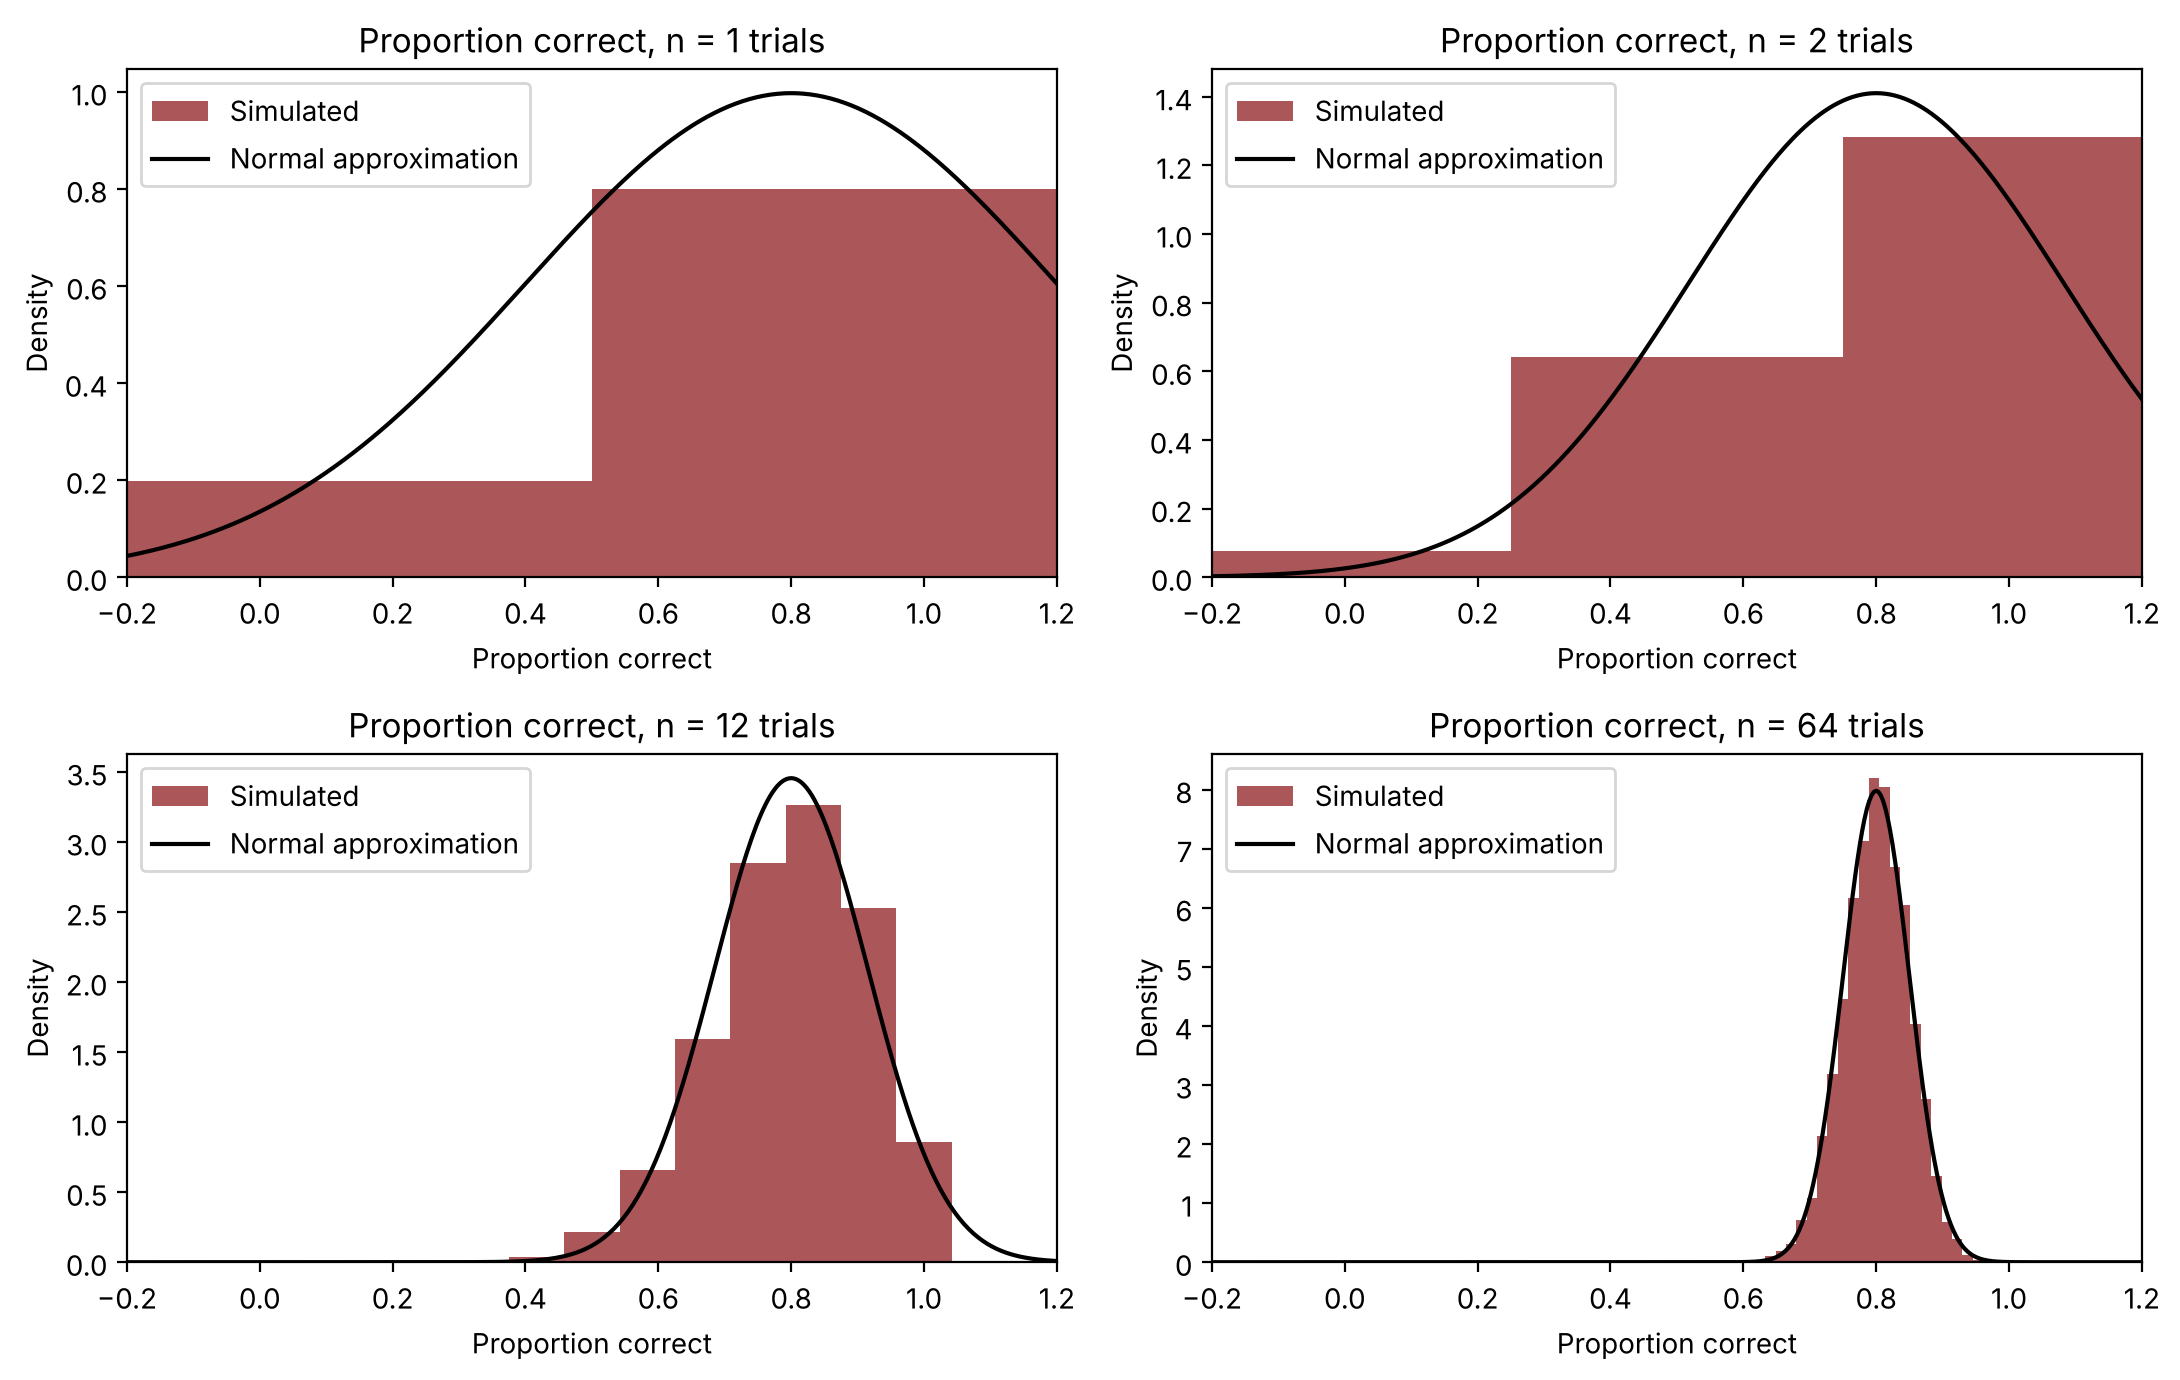

In [2]:
rng = np.random.default_rng(5)

p = 0.8
trial_counts = [1, 2, 12, 64]
n_participants = 10_000

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, n in zip(axes.ravel(), trial_counts):
    trials = rng.binomial(1, p, size=(n_participants, n))
    proportions = trials.mean(axis=1)
    theoretical_se = np.sqrt(p * (1 - p) / n)

    print(f"n = {n:2d}: mean = {proportions.mean():.3f}, SD = {proportions.std():.4f}, "
          f"theory SE = {theoretical_se:.4f}, skewness = {stats.skew(proportions):.2f}")

    bin_edges = (np.arange(n + 2) - 0.5) / n
    ax.hist(proportions, bins=bin_edges, density=True, color="#8f1d21", alpha=0.75,
            label="Simulated")
    grid = np.linspace(-0.2, 1.2, 400)
    ax.plot(grid, stats.norm.pdf(grid, p, theoretical_se), color="black",
            label="Normal approximation")
    ax.set_title(f"Proportion correct, n = {n} trials")
    ax.set_xlabel("Proportion correct")
    ax.set_ylabel("Density")
    ax.set_xlim(-0.2, 1.2)
    ax.legend()

plt.tight_layout()
plt.show()


### Interpretation questions

1. Describe the sampling distribution for $n=1$ and $n=2$. Why does the normal curve fit poorly?
2. How do shape and skewness change for $n=12$ and $n=64$?
3. Compare the simulated SDs with the theoretical $SE=\sqrt{p(1-p)/n}$.
4. Change `p` from 0.8 to 0.5. For which $n$ does the normal approximation now look good? Why do values of $p$ near 0 or 1 need more trials?
5. Connect the result for $n=64$ to Part 1, Question 2.


### Model interpretation

1. For $n=1$, the proportion is either 0 or 1 (about 20% vs. 80%). For $n=2$, it takes only 0, 0.5, or 1. These distributions are discrete and left-skewed (skewness about $-1.5$ and $-1.1$), so a smooth symmetric normal curve cannot describe them.

2. As $n$ grows, the bars "fill in" the normal curve. Skewness shrinks to about $-0.41$ for $n=12$ and $-0.14$ for $n=64$, and the distribution becomes narrower.

3. The simulated SDs (about 0.399, 0.281, 0.117, 0.050) agree closely with the theoretical values (0.400, 0.283, 0.115, 0.050). The standard error shrinks with $\sqrt n$.

4. With $p=0.5$, the Bernoulli distribution is symmetric, so the approximation already looks reasonable at $n=12$. When $p$ is near 0 or 1, the distribution is strongly skewed and bounded close to one end, so more trials are needed before the sample mean looks normal. This is why proportion tests require conditions such as $np_0\ge10$ and $n(1-p_0)\ge10$.

5. For $n=64$, the simulated mean is about 0.80 and the SD about 0.050, exactly the values $E(\hat p)=0.8$ and $SE=0.05$ computed by hand.


## Q2: Coverage of confidence intervals

We draw many samples from a normal population ($\mu=500$ ms, $\sigma=50$ ms), build a 95% interval from each sample using either the $t$ or the $z$ critical value (always with $s$ instead of $\sigma$), and count how often the interval contains $\mu$.


   n   t crit  t coverage  z coverage  t-CI width (ms)
   5    2.776       0.950       0.879            116.6
  10    2.262       0.949       0.917             69.3
  30    2.045       0.952       0.942             37.0
 100    1.984       0.947       0.945             19.8


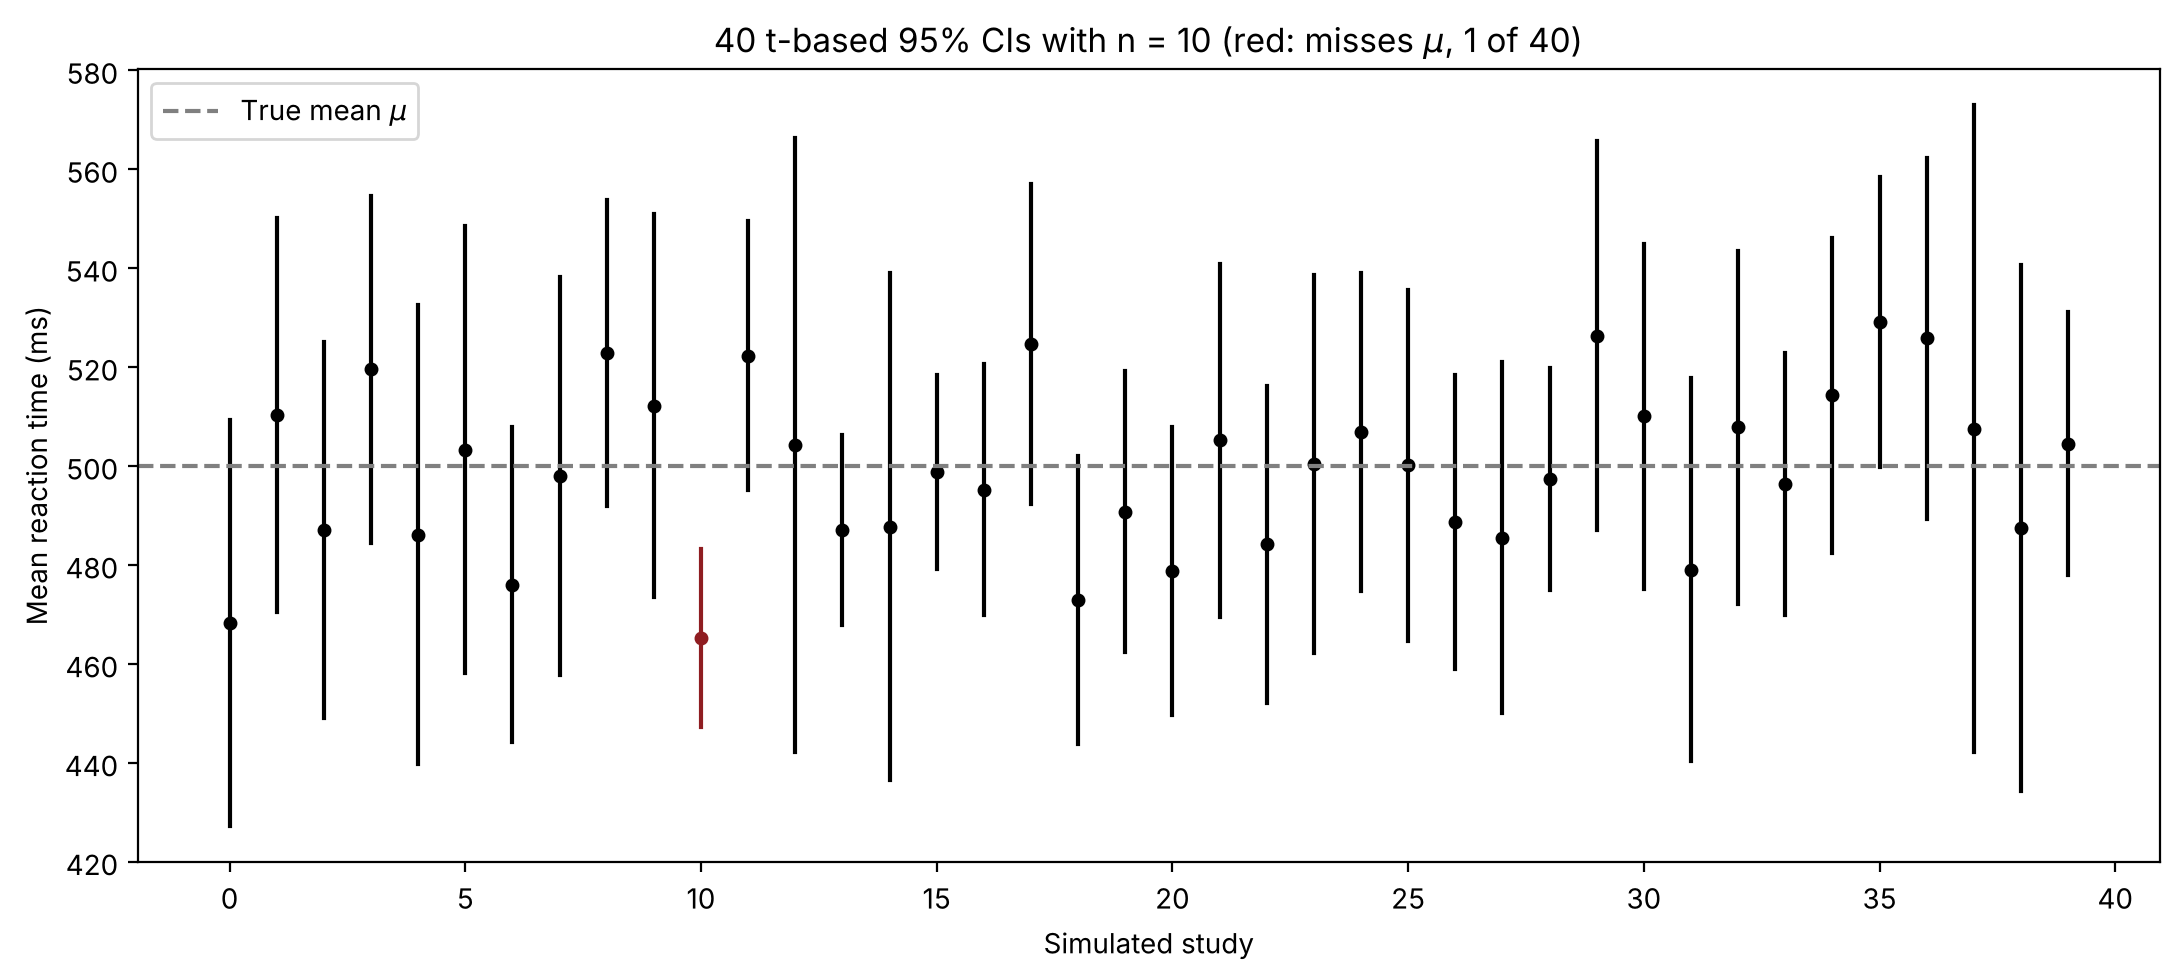

In [3]:
rng = np.random.default_rng(21)
mu, sigma = 500, 50


def coverage(n, n_sims=10_000):
    samples = rng.normal(mu, sigma, size=(n_sims, n))
    xbar = samples.mean(axis=1)
    se = samples.std(axis=1, ddof=1) / np.sqrt(n)
    t_crit = stats.t.ppf(0.975, df=n - 1)
    t_coverage = np.mean(np.abs(xbar - mu) <= t_crit * se)
    z_coverage = np.mean(np.abs(xbar - mu) <= 1.96 * se)
    mean_width = np.mean(2 * t_crit * se)
    return t_crit, t_coverage, z_coverage, mean_width


print(f"{'n':>4}{'t crit':>9}{'t coverage':>12}{'z coverage':>12}{'t-CI width (ms)':>17}")
for n in [5, 10, 30, 100]:
    t_crit, t_cov, z_cov, width = coverage(n)
    print(f"{n:4d}{t_crit:9.3f}{t_cov:12.3f}{z_cov:12.3f}{width:17.1f}")

# Plot 40 t-based intervals for n = 10
n, n_show = 10, 40
samples = rng.normal(mu, sigma, size=(n_show, n))
xbar = samples.mean(axis=1)
half_width = stats.t.ppf(0.975, df=n - 1) * samples.std(axis=1, ddof=1) / np.sqrt(n)
misses = np.abs(xbar - mu) > half_width

fig, ax = plt.subplots(figsize=(11, 5))
for i in range(n_show):
    color = "#8f1d21" if misses[i] else "black"
    ax.plot([i, i], [xbar[i] - half_width[i], xbar[i] + half_width[i]], color=color)
    ax.plot(i, xbar[i], "o", color=color, markersize=4)
ax.axhline(mu, color="grey", linestyle="--", label="True mean $\\mu$")
ax.set_title(f"40 t-based 95% CIs with n = 10 (red: misses $\\mu$, {misses.sum()} of {n_show})")
ax.set_xlabel("Simulated study")
ax.set_ylabel("Mean reaction time (ms)")
ax.legend()
plt.tight_layout()
plt.show()


### Interpretation questions

1. Why does the $t$-based coverage stay close to 0.95 for every $n$?
2. Why is the $z$-based coverage too low for small $n$, and why does the gap disappear for larger $n$?
3. How does the average interval width change from $n=10$ to $n=100$? Relate this to $\sqrt n$.
4. In the plot, how many intervals miss $\mu$? Is this surprising?
5. In a real study you see only one interval. Can you tell whether it is one of the misses?


### Model interpretation

1. The $t$ critical value accounts for the extra uncertainty from estimating $\sigma$ with $s$. When the population is normal, the $t$ interval has exactly 95% coverage at every $n$. The simulation gives 0.947–0.952.

2. With $n=5$ the $z$ interval covers $\mu$ only about 88% of the time, and with $n=10$ about 92%. 1.96 is too small when $s$ is imprecise, so the intervals are too narrow. At $n=30$ (0.942) and $n=100$ (0.945) the $t$ critical value is close to 1.96, so both methods agree.

3. The width drops from about 69 ms to about 20 ms, a factor of about 3.5. Most of this comes from $\sqrt{100/10}\approx3.16$; the rest comes from the smaller $t$ critical value at larger $df$.

4. The plot title reports the number of misses (red intervals). With 40 intervals we expect about $0.05\times40=2$ misses, and small deviations from 2 are normal sampling variation.

5. No. $\mu$ is unknown in practice, so a single interval cannot be checked. The 95% describes how reliable the procedure is in the long run.


## Q3: The t distribution and its heavier tails

We compare $t$ densities with different degrees of freedom to the standard normal density and compute two-sided tail probabilities.


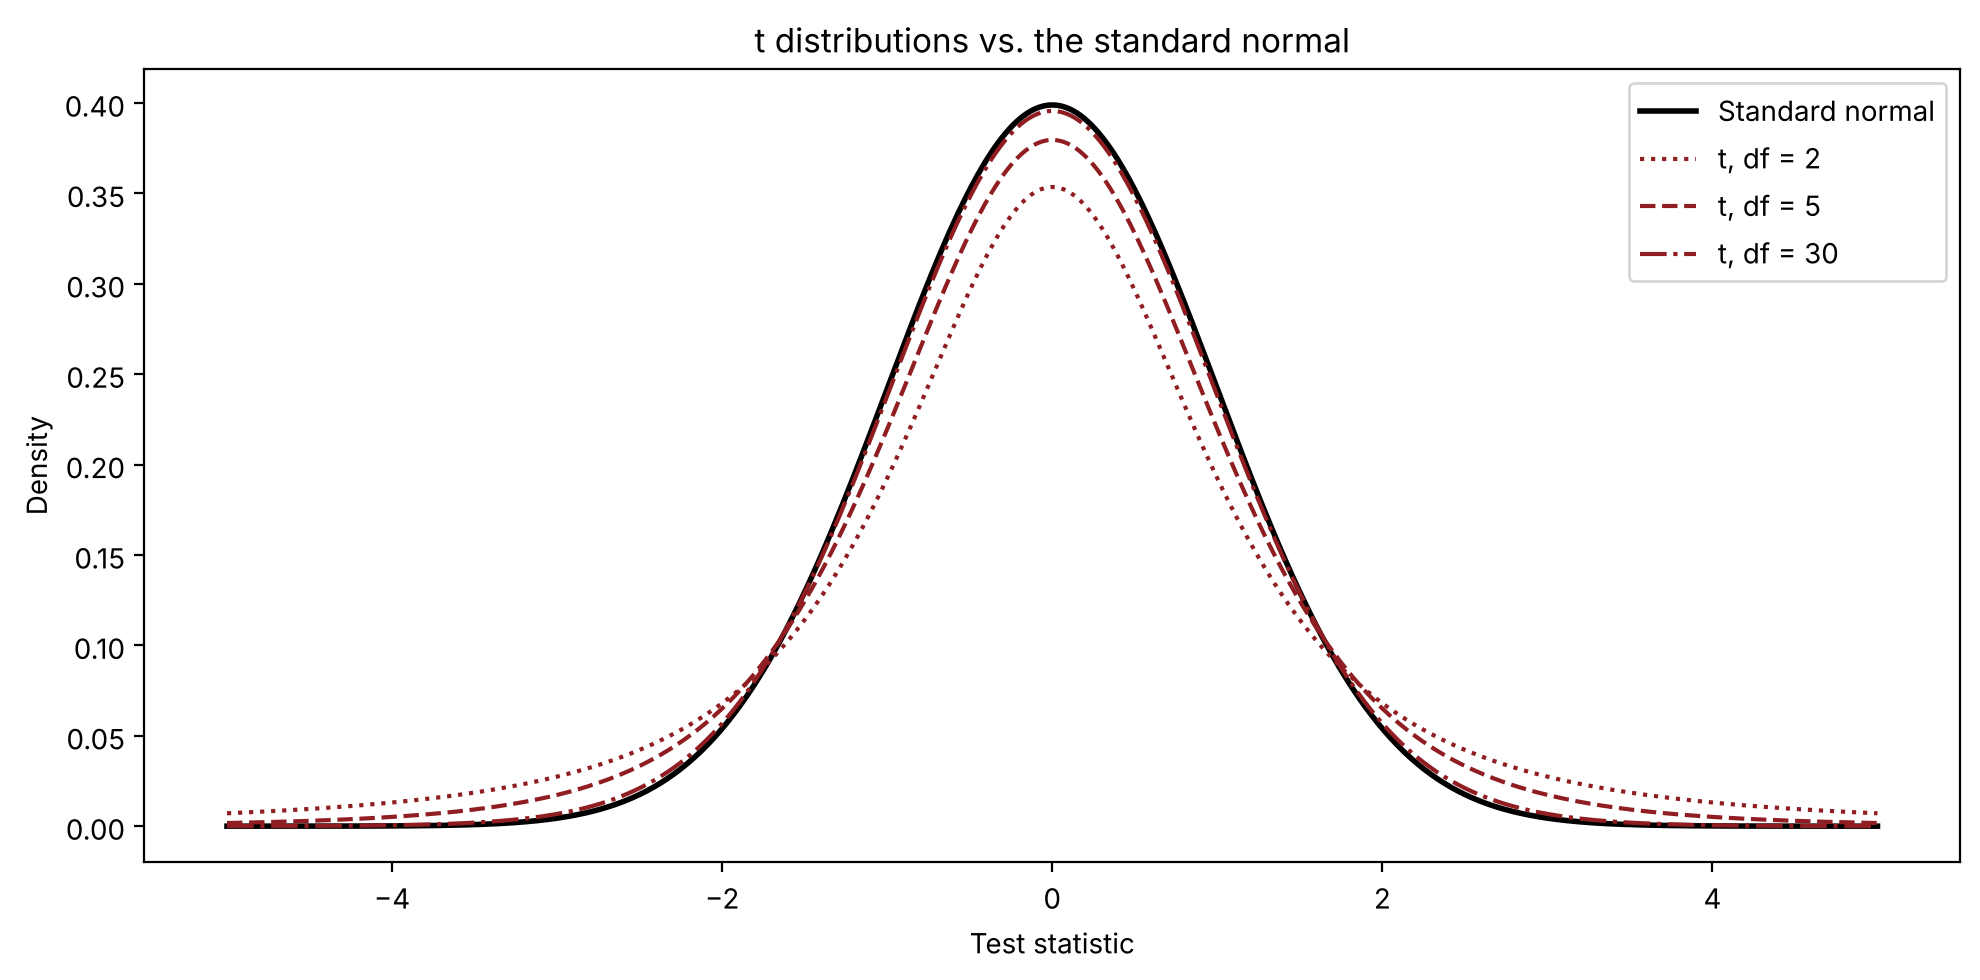

    df  t(0.975)   P(|T|>1.96)    P(|T|>3)
     2     4.303        0.1891      0.0955
     5     2.571        0.1073      0.0301
    10     2.228        0.0784      0.0133
    30     2.042        0.0593      0.0054
   100     1.984        0.0528      0.0034
normal     1.960        0.0500      0.0027


In [4]:
grid = np.linspace(-5, 5, 500)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(grid, stats.norm.pdf(grid), color="black", linewidth=2, label="Standard normal")
for df, style in [(2, ":"), (5, "--"), (30, "-.")]:
    ax.plot(grid, stats.t.pdf(grid, df), color="#8f1d21", linestyle=style, label=f"t, df = {df}")
ax.set_xlabel("Test statistic")
ax.set_ylabel("Density")
ax.set_title("t distributions vs. the standard normal")
ax.legend()
plt.tight_layout()
plt.show()

print(f"{'df':>6}{'t(0.975)':>10}{'P(|T|>1.96)':>14}{'P(|T|>3)':>12}")
for df in [2, 5, 10, 30, 100]:
    print(f"{df:6d}{stats.t.ppf(0.975, df):10.3f}"
          f"{2 * stats.t.sf(1.96, df):14.4f}{2 * stats.t.sf(3, df):12.4f}")
print(f"{'normal':>6}{stats.norm.ppf(0.975):10.3f}"
      f"{2 * stats.norm.sf(1.96):14.4f}{2 * stats.norm.sf(3):12.4f}")


### Interpretation questions

1. Describe how the $t$ density with df = 2 differs visually from the normal density.
2. Why does the $t$ distribution have heavier tails when df is small?
3. Suppose a test with df = 5 rejects whenever $|T|>1.96$. What is the actual Type I error rate?
4. From which df onwards is the normal approximation acceptable for a 5% two-sided test?
5. Compare $P(|T|>3)$ for df = 5 with the normal value. What does this mean for extreme test statistics?


### Model interpretation

1. Both are bell-shaped and symmetric around 0, but the df = 2 curve has a lower peak and much more probability in the tails.

2. The $t$ statistic divides by $s/\sqrt n$, and with few df, $s$ itself varies a lot between samples. Occasionally a small $s$ produces an extreme statistic, which shows up as heavier tails. As df increases, $s$ becomes stable and $t$ approaches the normal.

3. $P(|T|>1.96)\approx0.107$ for df = 5. The actual Type I error rate would be about 10.7% instead of 5%, more than double the nominal level. This is why small samples need $t$ critical values (2.571 here).

4. At df = 30, $P(|T|>1.96)\approx0.059$, and at df = 100 about 0.053. Around df ≈ 30, the normal approximation is close enough for most purposes, which matches the rule of thumb in the lecture ($N>30$).

5. For df = 5, $P(|T|>3)\approx0.030$, about 11 times the normal value of 0.0027. Values that would be extremely rare under the normal distribution are much less rare under a $t$ distribution with few df.
